# UEMR trên YouCook2: notebook bổ sung (Athena sạch `961f1a89`)

Theo `notebooks/uemr/UEMR_YC2_BO_SUNG.md`. Tiêu chí ghi trước: `configs/bo_sung_protocol.json`. Notebook checkout đúng `FUSHION_REF`
và `assert` sha256 của protocol bằng `PB_SHA16` (ô 1). Dùng lại cache của `uemr_final_AZ_clean.ipynb` (vector Omni, partition,
`az_state.json`); kết quả mới ở `uemr/results/961f1a89/bo_sung/`. Không ghi đè `results/961f1a89/`, `results/056d388e/` hay cache cũ:
vector mới chỉ được **thêm** vào store `raw/` (khoá `seg_key`), bảng gom ở thư mục `<hash>_bo_sung_<PHASE>` riêng.

**Hai lượt (`PHASE`).** Mọi lựa chọn trên dev được khoá bằng commit trước khi nhìn bất kỳ số val nào của phần bổ sung; val chấm đúng một lần.

| | `PHASE = 'dev'` (lượt 1) | `PHASE = 'val'` (lượt 2) |
|---|---|---|
| Ô chạy | 1–4 (thiết lập, kiểm tái lập), 5 (việc 2), 6 (việc 3), 7 (θ từng mức K: **chỉ đếm đoạn trên dev**; lưới R8 trên dev), 8 (chi phí), 9–10 (encode clip R8 **chỉ của 104 video dev**), 12 (chấm lưới R8 trên dev), 18 (**khối khoá** JSON) | 1–4, 7 (dựng partition từ cấu hình **đã khoá**), 8, 9–10, 11–17 (việc 4–10 trên val), 18 |
| Bỏ qua | 11, 13–17: không chấm val cho việc 4–10 | 5, 6 (đã chạy ở lượt 1) |
| Protocol | `viec4_budget.locked`, `viec5_R8.locked` phải là `null` | cả hai phải có (thiếu: **dừng**, không chọn lại) |

Sau lượt 1: gửi log; khối khoá ở ô 18 được chép vào `bo_sung_protocol.json`, commit; đổi `PHASE`, `FUSHION_REF`, `PB_SHA16` rồi chạy
lượt 2.

**Cách chạy:** Runtime **A100**, **Run all**. Ngắt giữa chừng: Run all lại (encode ghi store theo lô 200 clip và bỏ qua clip đã có;
CLIP ghi theo lô 25 video). Gửi log **mọi ô**. Ô 4–8, 11–13, 17, 18 chỉ cần CPU (đọc Drive); 10, 14–16 cần GPU khi còn clip phải encode.

In [1]:
# ===== 1. Lượt, ref code, cờ =====
PHASE       = 'val'           # 'dev' (lượt 1): chỉ chọn trên dev | 'val' (lượt 2): chấm val việc 4-10 đúng một lần
FUSHION_REF = '337eb8193f5e777ee231dac323529e91239de58e'       # commit chứa configs/bo_sung_protocol.json của lượt này
PB_SHA16    = '12daed1203e55fea'       # sha256[:16] của configs/bo_sung_protocol.json tại FUSHION_REF
RUN_CHECK   = True    # việc 2: tỉ lệ bỏ sót, K_pred, tIoU của R6 (lượt dev, CPU)
RUN_CI      = True    # việc 3: CI còn thiếu, từ vector đã cache (lượt dev, CPU)
RUN_BUDGET  = True    # việc 4: dev chọn θ từng mức K (đếm đoạn); val: R6_K / R3_K (A100: encode Omni ft)
RUN_R8      = True    # việc 5: dev lưới R8 (encode clip dev); val: R8 đã khoá
RUN_R5B     = True    # việc 6: R5b (lượt val, A100)
RUN_PT      = True    # việc 7: Omni pt (lượt val, A100 nếu thiếu cache)
RUN_AUDIO   = True    # việc 8: bỏ âm thanh lúc suy luận, phía Omni (lượt val, A100)
RUN_CLIP    = True    # việc 9: CLIP ViT-L/14 zero-shot (lượt val, A100)
RUN_CLIPRET = True    # việc 10: text -> clip GT (lượt val, CPU; cột pt cần RUN_PT, cột CLIP cần RUN_CLIP)
assert PHASE in ('dev', 'val'), PHASE
FLAGS = {k: v for k, v in dict(globals()).items() if k.startswith('RUN_') or k in ('PHASE', 'FUSHION_REF', 'PB_SHA16')}


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# ===== 3. Code, đường dẫn, sha256, phiên bản, unit test =====
import os, sys, shutil, json, subprocess, time, glob, zipfile, hashlib, platform
from collections import Counter, defaultdict
from pathlib import Path
T_START = time.time()
FUSHION_GIT = 'https://github.com/chien24/Fushion_UEMR.git'
FUSHION     = '/content/code/Fushion_UEMR'
%cd /content
os.makedirs('/content/code', exist_ok=True)
shutil.rmtree(FUSHION, ignore_errors=True)
!git clone -q {FUSHION_GIT} {FUSHION}
git = lambda *a: subprocess.run(['git', '-C', FUSHION, *a], capture_output=True, text=True).stdout.strip()
r = subprocess.run(['git', '-C', FUSHION, 'checkout', '-q', FUSHION_REF], capture_output=True, text=True)
assert r.returncode == 0, f'không checkout được FUSHION_REF={FUSHION_REF}: {r.stderr}'
COMMIT = git('log', '--oneline', '-1')
print('HEAD:', git('rev-parse', 'HEAD'), '|', COMMIT, '| PHASE:', PHASE)
PB_COMMIT = git('log', '-1', '--format=%h %ad', '--date=short', '--', 'configs/bo_sung_protocol.json')
print('code:', COMMIT, '| commit ghi bo_sung_protocol.json:', PB_COMMIT)
if FUSHION not in sys.path:
    sys.path.insert(0, FUSHION)
os.environ['PYTHONPATH'] = FUSHION + ':' + os.environ.get('PYTHONPATH', '')
%cd {FUSHION}
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import display
from omni_retrieval.protocol import P as PROTO, PATH as PROTO_PATH
from omni_retrieval.config import Config
from omni_retrieval.collect import collect_segments, local_npz
from omni_retrieval.evaluate import gallery_videos, load_text, load_index, paired_bootstrap, text_to_clip, video_ranks
from omni_retrieval.manifest import prepare, read_store, segment_records, store_keys, unique_segments, write_jsonl
from omni_retrieval.partitions import uniform
from omni_retrieval.partitions_uemr import HALF_WINDOW, _round, best_tiou, coverage, kmedoids, miss_rate, video_rng, window
from omni_retrieval.search import tiou_vec
from omni_retrieval.bo_sung import centred_windows, fill_gaps, frame_index, overlap, pick_fill, pick_level
from uniav_app.postprocess import postprocess_uemr

BASE       = '/content/drive/MyDrive/Colab Notebooks/code KL/Fushion/uemr'
O, U       = f'{BASE}/omni_cache', f'{BASE}/uniav_cache'
DRIVE_DATA = '/content/drive/MyDrive/Colab Notebooks/code KL/Omni/data/YouCookII'
META, VIDEO_SRC = f'{DRIVE_DATA}/metadata', f'{DRIVE_DATA}/videos'
P0, SUBSET = f'{O}/common/partitions', f'{O}/common/subset_videos.json'
STATE_PATH = f'{BASE}/az_state.json'
CKPT_SRC   = '/content/drive/MyDrive/Colab Notebooks/code KL/Omni/checkpoint-1948'
CKPT, ORIG_ADAPTER = '/content/my_checkpoint', '/content/adapters/omniretriever-7b'
BASE_MODEL = '/content/WAVE_HOME/WAVE-7B'
BEATS      = '/content/WAVE_HOME/BEATs_iter3_plus_AS2M_finetuned_on_AS2M_cpt2.pt'
ATHENA_CKPT = f'{BASE}/athena_sach/961f1a89/athena_yc2clean.pth'
ATHENA_SHA  = '961f1a895f4b43c811d3e0cfa31448641989a0a0e39e421ed397682407643d58'
ATHENA_H8   = ATHENA_SHA[:8]
RES_NEW, RES_OLD = f'{BASE}/results/{ATHENA_H8}', f'{BASE}/results/056d388e'
BS = f'{RES_NEW}/bo_sung'
os.makedirs(BS, exist_ok=True)

def sha256(path, bs=1 << 24):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(bs), b''):
            h.update(chunk)
    return h.hexdigest()

PB_PATH = f'{FUSHION}/configs/bo_sung_protocol.json'
PB, PB_SHA, PROTO_SHA = json.load(open(PB_PATH)), sha256(PB_PATH)[:16], sha256(PROTO_PATH)[:16]
assert PB_SHA == PB_SHA16, f'bo_sung_protocol.json tại {FUSHION_REF} có sha {PB_SHA}, notebook ghi {PB_SHA16}'
assert PROTO_SHA == '133125b9549bc74a' == PB['inputs']['final_protocol_sha256_16'], f'final_protocol.json đã đổi: {PROTO_SHA}'
assert PB_COMMIT, 'configs/bo_sung_protocol.json chưa được commit'
assert sha256(ATHENA_CKPT) == ATHENA_SHA == PB['inputs']['athena_sha256'], 'checkpoint Athena khác sha256'
st = json.load(open(STATE_PATH))['new']
assert st['athena_sha256'] == ATHENA_SHA, 'az_state.json không phải lượt AZ của Athena sạch'
H8 = st['hash8']                                    # vân tay đầu ra UniAV (AZ mục 2)
UG, PG = f'{U}/ft_{H8}', f'{O}/common/partitions_{H8}'
DBH, DBH_PT = f'{O}/ft/{H8}', f'{O}/pt/{H8}'
RAW_PATH = f'{U}/athena_{ATHENA_H8}/raw_proposals.jsonl'   # soft-NMS, trước θ (B1 ô 6)
L4, LOCKED = PB['viec4_budget']['locked'], PB['viec5_R8']['locked']
if PHASE == 'dev':
    assert L4 is None and LOCKED is None, 'protocol đã có cấu hình khoá: lượt dev không chọn lại (đặt PHASE = "val")'
else:
    assert (L4 or not RUN_BUDGET) and (LOCKED or not RUN_R8), \
        'DỪNG: protocol chưa có cấu hình khoá của lượt dev (viec4_budget.locked, viec5_R8.locked): không tự chọn lại'
LOCK_BLOCK = {}                                      # lượt dev: khối in ở ô 18 để chép vào protocol
print(json.dumps({'final_protocol': PROTO_SHA, 'bo_sung_protocol': PB_SHA, 'athena': ATHENA_H8, 'uniav hash': H8,
                  'θ việc 4 đã khoá': L4, 'R8 đã khoá': LOCKED}, ensure_ascii=False))

gpu = subprocess.run('nvidia-smi --query-gpu=name --format=csv,noheader', shell=True, capture_output=True, text=True).stdout.strip()
ENV = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'torch': torch.__version__,
       'gpu': gpu or 'không có (CPU)'}
print(json.dumps(ENV, indent=1))
r = subprocess.run([sys.executable, '-m', 'pytest', 'omni_retrieval/tests', '-q', '-p', 'no:cacheprovider'], cwd=FUSHION,
                   capture_output=True, text=True)
print(r.stdout[-800:])
assert r.returncode == 0, 'unit test chưa qua: dừng'

def sh(cmd, check=True):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr)[-3000:]
    if out.strip():
        print(out)
    if check and r.returncode:
        raise RuntimeError(f'lệnh lỗi ({r.returncode}): {cmd[:200]}')
    return r

def omni_cfg(tag, **kw):
    return Config.colab(tag=tag, n_videos=500, seed=0, cache_root=O, drive_data=DRIVE_DATA, meta_dir=META, video_src=VIDEO_SRC,
                        wave_path=BASE_MODEL, beats_path=BEATS, adapter_ft=CKPT, adapter_pt=ORIG_ADAPTER, **kw)

def ci(lo, hi):
    return f'[{lo:+.2f}, {hi:+.2f}]'

def boot(a, b, vids, k=1):
    bs = paired_bootstrap(a, b, k, PB['rules']['bootstrap']['n_boot'], PB['rules']['bootstrap']['seed'], 'video', vids)
    return {'A - B': bs['diff'], 'CI (video)': ci(bs['ci_low'], bs['ci_high']), 'ci_low': bs['ci_low'], 'ci_high': bs['ci_high']}

TXT, RK = {}, {}
def tx_of(db, gallery):
    # caption của chính db (Omni ft / pt / CLIP), cùng thứ tự với text.npz của AZ
    f = 'text_dev.npz' if gallery == 'dev' else 'text.npz'
    if (db, f) not in TXT:
        t = load_text(db, f)
        assert np.array_equal(t['caption_id'], (text_dev if gallery == 'dev' else text)['caption_id']), f'{db}/{f}: thứ tự caption khác'
        TXT[(db, f)] = t
    return TXT[(db, f)]

def ranks(db, p, gallery='val'):
    # (rank video đúng, VCMR hit tIoU 0.5, vector/video) mỗi caption; gallery 'val' (394), 'all' (498), 'dev' (104, caption dev)
    key = (db, p, gallery)
    if key not in RK:
        tx = tx_of(db, gallery)
        idx = load_index(db, p, {'val': VAL, 'dev': DEV, 'all': None}[gallery])
        r = video_ranks(idx, tx)
        hit = (r['ranks'] == 1) & r['covered'] & (tiou_vec(r['best_ts'], r['best_te'], tx['gt_ts'], tx['gt_te']) >= 0.5)
        RK[key] = (r['ranks'], hit, float(np.mean(idx.counts)))
    return RK[key]

def r_at(rk, k=1):
    return 100 * float((np.asarray(rk) <= k).mean())

def pair(db_a, a, db_b, b, gallery='val', k=1, vcmr=False):
    (ra, ha, _), (rb, hb, _) = ranks(db_a, a, gallery), ranks(db_b, b, gallery)
    if vcmr:
        ra, rb = np.where(ha, 1, 2), np.where(hb, 1, 2)
    return boot(ra, rb, (text_dev if gallery == 'dev' else text)['video_id'], k)

def db_rows(db, parts, videos):
    # dòng segments.npz (partition, seg_key) của các video; ts, te đọc từ seg_key: đúng cửa sổ đã encode
    with np.load(f'{db}/segments.npz') as b:
        m = np.isin(b['partition'], list(parts)) & np.isin(b['video_id'], list(videos))
        out = []
        for k, sk, v, p in zip(b['keys'][m].tolist(), b['seg_key'][m].tolist(), b['video_id'][m].tolist(), b['partition'][m].tolist()):
            ts, te = map(float, sk.rsplit('__', 1)[1].split('_'))
            out.append({'key': k, 'seg_key': sk, 'video_id': v, 'partition': p, 'ts': ts, 'te': te})
    return out

def fresh_db(rows, store, local, drive_dir, texts=()):
    # segments.npz của rows ở local: bản trên Drive nếu khớp từng (partition, seg_key), không thì gom lại từ store
    os.makedirs(local, exist_ok=True); os.makedirs(drive_dir, exist_ok=True)
    for src, f in texts:
        shutil.copy2(src, f'{local}/{f}')
    want = Counter((r['partition'], r['seg_key']) for r in rows)
    def ok(p):
        if not zipfile.is_zipfile(p):
            return False
        with np.load(p) as b:
            return Counter(zip(b['partition'].tolist(), b['seg_key'].tolist())) == want
    loc, drv = f'{local}/segments.npz', f'{drive_dir}/segments.npz'
    if not ok(loc):
        if os.path.exists(drv):
            shutil.copy2(drv, loc)
        if not ok(loc):
            print('[db] gom lại:', collect_segments(rows, store, Path(loc)))
            assert ok(loc)
            shutil.copy2(loc, drv)
    return local

LABEL = {'global': 'R0', 'uni_chunk': 'R2', 'uni_M': 'R3', 'kmedoids_M': 'R5', 'uniav_pred': 'R6', 'gt': 'R7',
         'uniav_pred+uni_chunk': 'R6 ∪ R2', 'r8': 'R8', 'r5b': 'R5b'}
MAIN, CLIP_OK = None, False             # việc 5 (lượt val), việc 9
OUT = {}                                             # bảng của từng việc -> so_lieu_bo_sung.md
MAN_PATH = f'{BS}/run_manifest.json'
MAN = json.load(open(MAN_PATH)) if os.path.exists(MAN_PATH) else {'runs': []}
RUN = {'started': time.strftime('%Y-%m-%d %H:%M:%S'), 'commit': COMMIT, 'final_protocol_sha16': PROTO_SHA,
       'phase': PHASE, 'fushion_ref': FUSHION_REF, 'head': git('rev-parse', 'HEAD'),
       'bo_sung_protocol': {'sha16': PB_SHA, 'commit': PB_COMMIT, 'viec4 locked': L4, 'R8 locked': LOCKED}, 'athena_sha256': ATHENA_SHA,
       'uniav_hash8': H8, 'flags': FLAGS, 'env': ENV, 'encoded': {}, 'sec': {}, 'info': {}}

def done(part, t0, **info):
    RUN['sec'][part] = round(time.time() - t0, 1)
    RUN['info'][part] = info
    json.dump({**MAN, 'runs': MAN['runs'] + [RUN]}, open(MAN_PATH, 'w'), indent=1, default=str, ensure_ascii=False)
    print(f'[manifest] {part}: {RUN["sec"][part]} s')

/content
HEAD: 337eb8193f5e777ee231dac323529e91239de58e | 337eb81 bo_sung_protocol: khoá θ việc 4 (5 mức) và R8 (L_min 5, L_fill 10) từ lượt dev; notebook kèm output lượt dev | PHASE: val
code: 337eb81 bo_sung_protocol: khoá θ việc 4 (5 mức) và R8 (L_min 5, L_fill 10) từ lượt dev; notebook kèm output lượt dev | commit ghi bo_sung_protocol.json: 337eb81 2026-10-22
/content/code/Fushion_UEMR
{"final_protocol": "133125b9549bc74a", "bo_sung_protocol": "12daed1203e55fea", "athena": "961f1a89", "uniav hash": "a793d2c4", "θ việc 4 đã khoá": [{"K mục tiêu": 7.5, "method": "theta", "param": 0.4, "K dev": 6.990384615384615, "đạt": true, "vec/video dev": 6.990384615384615, "độ phủ % dev": 50.76569127316611, "chồng lấn % dev": 3.007658581937807}, {"K mục tiêu": 10, "method": "theta", "param": 0.34, "K dev": 9.875, "đạt": true, "vec/video dev": 9.875, "độ phủ % dev": 59.38336350531753, "chồng lấn % dev": 8.89216148378575}, {"K mục tiêu": 14, "method": "theta", "param": 0.285, "K dev": 14.0192307692

## Kiểm tái lập (kho val 394, Omni `ft`)

Cùng `segments.npz` của AZ (`omni_cache/ft/<hash UniAV>`). Lệch số tham chiếu quá 0.005 hoặc thứ tự R6 > R3, R6 > R0 (cận dưới CI > 0)
không giữ: **dừng**.

In [4]:
# ===== 4. Nạp cache AZ, kiểm tái lập =====
t0 = time.time()
sub = json.load(open(SUBSET))['videos']
dur = {r['video_id']: float(r['duration']) for r in sub}
VAL, DEV = gallery_videos(SUBSET, 'val'), gallery_videos(SUBSET, 'dev')
assert (len(dur), len(VAL), len(DEV)) == (498, 394, 104)
NEED_AZ = ('global', 'uni_M', 'uni_chunk', 'kmedoids_M', 'uniav_pred', 'gt', 'uniav_pred+uni_chunk')
DB = str(local_npz(DBH, f'/content/db_ft_{H8}', ('segments.npz', 'text.npz', 'text_dev.npz'), NEED_AZ))
text, text_dev = load_text(DB), load_text(DB, 'text_dev.npz')
assert (len(text['emb']), len(text_dev['emb'])) == (3030, 773)
REF = PB['reproduce_val394_R@1_ft']
got = {p: r_at(ranks(DB, p)[0]) for p in REF if p != 'tol'}
print('R@1 val 394 (tham chiếu AZ):', {LABEL[p]: f'{v:.2f} ({REF[p]})' for p, v in got.items()})
bad = {p: (round(v, 3), REF[p]) for p, v in got.items() if abs(v - REF[p]) > REF['tol']}
assert not bad, f'DỪNG: không tái lập được số của AZ {bad}'
ORDER = {f'R6 − {LABEL[p]}': pair(DB, 'uniav_pred', DB, p) for p in ('uni_M', 'global')}
display(pd.DataFrame(ORDER).T[['A - B', 'CI (video)']].round(2))
assert all(v['ci_low'] > 0 for v in ORDER.values()), 'DỪNG: thứ tự R6 > R3 hoặc R6 > R0 không giữ: báo người dùng'
r6 = json.load(open(f'{PG}/uniav_pred.json'))
gt0 = json.load(open(f'{P0}/gt.json'))
gt_val = {v: gt0[v] for v in sorted(VAL)}
MISS_T = PROTO['eval']['miss_tiou']
# max tIoU giữa event GT của từng caption val và các đoạn R6 cùng video (việc 2, nhóm của việc 5)
BT_Q = np.array([float(tiou_vec(np.array(r6[v])[:, 0], np.array(r6[v])[:, 1], a, b).max())
                 for v, a, b in zip(text['video_id'], text['gt_ts'], text['gt_te'])])
MISSED_Q = BT_Q < MISS_T
OUT['tái lập'] = pd.DataFrame([{'dòng': LABEL[p], 'R@1': v, 'tham chiếu': REF[p]} for p, v in got.items()])
done('tai_lap', t0, R1=got, order={k: v['CI (video)'] for k, v in ORDER.items()})

R@1 val 394 (tham chiếu AZ): {'R0': '8.32 (8.32)', 'R3': '18.02 (18.02)', 'R2': '27.16 (27.16)', 'R6': '24.52 (24.52)', 'R7': '37.52 (37.52)'}


,A - B,CI (video)
R6 − R3,6.50165,"[+4.51, +8.47]"
R6 − R0,16.20462,"[+14.26, +18.22]"


[manifest] tai_lap: 19.4 s


## Việc 2: kiểm lại tỉ lệ bỏ sót (CPU, lượt dev)

File kết quả ghi "R6 bỏ sót 27.16% event GT của val (AZ ô 12)", trùng R@1 của R2 (27.16), còn bảng UniAV (AZ ô 10, ô 39) ghi 27.19.
Ở đây tính cả hai định nghĩa (theo event GT, theo câu hỏi) và cả hai nguồn đoạn (`uniav_pred.json` đã làm tròn theo mp4,
`segments_pred.jsonl` thô), in tử số / mẫu số để thấy chỗ trùng.

In [5]:
# ===== 5. Việc 2 =====
if RUN_CHECK and PHASE == 'dev':
    t0 = time.time()
    os.makedirs(f'{BS}/viec2', exist_ok=True)
    pred_raw = defaultdict(list)
    for l in open(f'{UG}/segments_pred.jsonl'):
        if l.strip():
            q = json.loads(l)
            pred_raw[q['video_id']].append([float(q['ts']), float(q['te'])])
    bt_ev = best_tiou({v: r6[v] for v in VAL}, gt_val)
    bt_raw = best_tiou({v: pred_raw[v] for v in VAL}, gt_val)
    r2_hit = int((ranks(DB, 'uni_chunk')[0] == 1).sum())
    uni = pd.read_csv(f'{RES_NEW}/uniav_stats.csv', index_col=0)
    t2 = pd.DataFrame([
        {'định nghĩa': 'theo event GT; đoạn R6 = uniav_pred.json (làm tròn 2 chữ số theo mp4); như AZ ô 12', 'bỏ sót': int((bt_ev < MISS_T).sum()),
         'tổng': len(bt_ev), '%': 100 * float((bt_ev < MISS_T).mean())},
        {'định nghĩa': 'theo event GT; đoạn = segments_pred.jsonl thô; như AZ ô 10 / ô 39', 'bỏ sót': int((bt_raw < MISS_T).sum()),
         'tổng': len(bt_raw), '%': 100 * float((bt_raw < MISS_T).mean())},
        {'định nghĩa': 'theo câu hỏi; event GT của câu (gt_ts, gt_te), đoạn R6 = uniav_pred.json', 'bỏ sót': int(MISSED_Q.sum()),
         'tổng': len(MISSED_Q), '%': 100 * float(MISSED_Q.mean())},
        {'định nghĩa': '(đối chiếu) R2 uni_chunk R@1: số câu đúng top-1', 'bỏ sót': r2_hit, 'tổng': len(MISSED_Q),
         '%': 100 * r2_hit / len(MISSED_Q)}])
    display(t2.round(2))
    print('AZ: ô 12 (MISS val) 27.16 | ô 10 / ô 39 (uniav_stats.csv):', uni.loc['val', 'GT bỏ sót % (tIoU < 0.3)'])
    S2 = {'K_pred R6 trung bình (val 394)': float(np.mean([len(r6[v]) for v in VAL])),
          'tIoU R6 trung bình (event GT val)': float(bt_ev.mean()), 'tIoU R6 trung bình (caption val)': float(BT_Q.mean()),
          'event GT val': int(len(bt_ev)), 'caption val': int(len(BT_Q)),
          'event GT val khác nhau (video, ts, te)': len({(v, *s) for v in VAL for s in gt0[v]})}
    print(json.dumps(S2, indent=1, ensure_ascii=False))
    t2.to_csv(f'{BS}/viec2/miss.csv', index=False)
    json.dump(S2, open(f'{BS}/viec2/r6_val.json', 'w'), indent=1, ensure_ascii=False)
    pd.DataFrame({'caption_id': text['caption_id'], 'video_id': text['video_id'], 'best_tiou_r6': BT_Q,
                  'missed': MISSED_Q}).to_csv(f'{BS}/viec2/per_query_miss.csv', index=False)
    OUT['việc 2'] = t2
    done('viec2', t0, **S2)

## Việc 3: CI còn thiếu (CPU, lượt dev)

Vector đã cache: Athena cũ `omni_cache/ft/segments.npz` (layout gốc, `results/056d388e`), Athena sạch `omni_cache/ft/<hash>`.
Cùng 3.030 caption, bootstrap theo video. Kiểm trước: thứ hạng R6 tính lại trùng `ranks_val394.npz` của cả hai thư mục kết quả.

In [6]:
# ===== 6. Việc 3 =====
if RUN_CI and PHASE == 'dev':
    t0 = time.time()
    os.makedirs(f'{BS}/viec3', exist_ok=True)
    DB_OLD = str(local_npz(f'{O}/ft', '/content/db_ft_old', ('segments.npz', 'text.npz'), ('uniav_pred', 'uni_chunk')))
    for R, db in ((RES_OLD, DB_OLD), (RES_NEW, DB)):
        k = np.load(f'{R}/ranks_val394.npz')
        assert np.array_equal(k['caption_id'], text['caption_id']) and np.array_equal(k['uniav_pred'], ranks(db, 'uniav_pred')[0]), \
            f'{R}: thứ hạng R6 tính lại khác ranks_val394.npz'
    KHO = {'val': 'val 394', 'all': '498'}
    rows3 = []
    for what, g, k, vc in (('R@5', 'val', 5, False), ('R@10', 'val', 10, False), ('VCMR R@1 (tIoU 0.5)', 'val', 1, True),
                           ('R@1', 'all', 1, False)):
        (ra, ha, _), (rb, hb, _) = ranks(DB, 'uniav_pred', g), ranks(DB_OLD, 'uniav_pred', g)
        rows3.append({'so sánh': 'R6 sạch − R6 cũ', 'chỉ số': what, 'kho': KHO[g],
                      'A': 100 * float(ha.mean()) if vc else r_at(ra, k), 'B': 100 * float(hb.mean()) if vc else r_at(rb, k),
                      **pair(DB, 'uniav_pred', DB_OLD, 'uniav_pred', g, k, vc)})
    for a, b, g in (('uniav_pred', 'uni_chunk', 'all'), ('uniav_pred+uni_chunk', 'uni_chunk', 'val'),
                    ('uniav_pred+uni_chunk', 'uni_chunk', 'all')):
        rows3.append({'so sánh': f'{LABEL[a]} − {LABEL[b]} (Athena sạch)', 'chỉ số': 'R@1', 'kho': KHO[g],
                      'A': r_at(ranks(DB, a, g)[0]), 'B': r_at(ranks(DB, b, g)[0]), **pair(DB, a, DB, b, g)})
    t3 = pd.DataFrame(rows3)
    display(t3.drop(columns=['ci_low', 'ci_high']).round(2))
    az = pd.read_csv(f'{RES_NEW}/exp1_b_bootstrap.csv')
    print('đối chiếu exp1_b_bootstrap.csv (AZ):')
    display(az[az.B.str.contains('uni_chunk') & az.A.str.contains('uniav_pred')][['split', 'A', 'B', 'A - B', 'CI (video)']].round(2))
    t3.to_csv(f'{BS}/viec3/ci.csv', index=False)
    OUT['việc 3'] = t3.drop(columns=['ci_low', 'ci_high'])
    done('viec3', t0)

## Dựng partition mới (CPU)

- Cả hai lượt: hậu xử lý `uemr` của UniAV (`postprocess_uemr`, k_max 30, d_min 2, merge 0.7) chạy lại trên `raw_proposals.jsonl`
  (soft-NMS, trước θ); `assert` θ của `theta.json` (0.40) ra đúng `uniav_pred.json`.
- **Lượt dev.** Việc 4: mỗi K mục tiêu, θ trên lưới 0.150–0.400 (bước 0.005) có K_pred trung bình **dev** gần K nhất (`pick_level`;
  top-k chỉ khi θ lệch > 0.5); mức 7.5 = θ của R6 hiện tại. **Chỉ đếm đoạn**, in độ phủ và chồng lấn trên dev, không encode. Việc 5:
  lưới `L_min` × `L_fill` cho 104 video dev.
- **Lượt val.** R6_K từ θ đã khoá (`assert` K trung bình dev bằng số đã khoá), R3_K cắt đều cùng số đoạn; R8 từ cấu hình đã khoá cho
  498 video; R5b: tính lại medoid của R5 (cùng seed), `assert` cửa sổ ±1 s trùng `kmedoids_M.json`, rồi cửa sổ thời lượng / K.

In [7]:
# ===== 7. Dựng partition mới =====
t0 = time.time()
PP = PROTO['uniav']['postprocess']
TH = json.load(open(f'{U}/athena_{ATHENA_H8}/theta.json'))          # θ của Athena sạch (B1 ô 7)
assert TH['chosen_on'] == 'dev' and TH['checkpoint_sha256'] == ATHENA_SHA
THETA0 = TH['theta']
PARTS_DIR = f'{BS}/partitions_{PHASE}'
os.makedirs(PARTS_DIR, exist_ok=True)
NEW = {}                                             # tên -> {video: [[ts, te], ...]}, ghi ra PARTS_DIR
raw = {}
for l in open(RAW_PATH):
    if l.strip():
        q = json.loads(l)
        raw[q['video_id']] = q                       # dòng sau cùng của mỗi video thắng (như latest_by)
assert set(dur) <= set(raw), 'raw_proposals.jsonl thiếu video gallery'

def post(v, theta, k_max):
    # đúng chuỗi của B1: postprocess_uemr -> segments_pred (3 chữ số) -> partitions_uemr._round (2 chữ số, <= mp4)
    segs = postprocess_uemr(raw[v]['proposals'], raw[v]['duration'], theta, k_max, PP['d_min'], PP['merge_tiou'])
    return _round([[round(float(s['ts']), 3), round(float(s['te']), 3)] for s in segs], dur[v])

def level_part(c, videos):
    return {v: post(v, c['param'], PP['k_max']) if c['method'] == 'theta' else post(v, 0.0, c['param']) for v in videos}

def shape(part, videos):
    vs = [v for v in videos if v in part]
    return {'video': len(vs), 'vec/video': float(np.mean([len(part[v]) for v in vs])),
            'độ phủ %': 100 * float(np.mean([coverage(part[v], dur[v]) for v in vs])),
            'chồng lấn %': 100 * float(np.mean([overlap(part[v]) for v in vs]))}

diff = [v for v in dur if post(v, THETA0, PP['k_max']) != r6[v]]
assert not diff, f'hậu xử lý lại θ {THETA0} khác uniav_pred.json ở {len(diff)} video: {diff[:5]}'
uni_M = json.load(open(f'{PG}/uni_M.json'))
tag_of = lambda K: f'{int(round(K * 10)):03d}'      # 7.5 -> 075, 10 -> 100

LEVELS = []
if RUN_BUDGET and PHASE == 'dev':
    B4 = PB['viec4_budget']
    g = B4['theta_grid']
    thetas = np.round(np.arange(g['start'], g['stop'] + 1e-9, g['step']), 3)
    CAND = [{'method': 'theta', 'param': float(t), 'K dev': float(np.mean([len(post(v, t, PP['k_max'])) for v in DEV]))} for t in thetas]
    CAND += [{'method': 'topk', 'param': k, 'K dev': float(np.mean([len(post(v, 0.0, k)) for v in DEV]))} for k in range(1, PP['k_max'] + 1)]
    pd.DataFrame(CAND).to_csv(f'{PARTS_DIR}/budget_dev_sweep.csv', index=False)
    for K in B4['targets_K']:
        c = ({'method': 'theta', 'param': THETA0, 'K dev': float(np.mean([len(r6[v]) for v in DEV]))} if K == 7.5
             else pick_level(CAND, K))
        ok = K == 7.5 or abs(c['K dev'] - K) <= 0.5
        sh_ = {f'{k} dev': x for k, x in shape(level_part(c, DEV), DEV).items() if k != 'video'}
        LEVELS.append({'K mục tiêu': K, **c, 'đạt': bool(ok), **sh_})
        if not ok:
            print(f'K = {K}: không đạt bằng θ lẫn top-k (gần nhất: {c})')
    lv = pd.DataFrame(LEVELS)
    print('=== việc 4: θ từng mức K, chọn trên dev (chỉ đếm đoạn, không encode) ==='); display(lv.round(3))
    hi = lv[lv['đạt']].sort_values('K mục tiêu')
    print(f"chồng lấn R6_K trên dev: {hi['chồng lấn % dev'].iloc[0]:.1f}% (K {hi['K mục tiêu'].iloc[0]}) -> "
          f"{hi['chồng lấn % dev'].iloc[-1]:.1f}% (K {hi['K mục tiêu'].iloc[-1]}); độ phủ {hi['độ phủ % dev'].iloc[0]:.1f}% -> "
          f"{hi['độ phủ % dev'].iloc[-1]:.1f}% (R3_K luôn phủ 100%, chồng lấn 0%)")
    assert max(l['K mục tiêu'] for l in LEVELS if l['đạt']) >= 14, 'DỪNG: không đạt K >= 14 bằng θ lẫn top-k: báo người dùng'
    LOCK_BLOCK['viec4_budget'] = {'locked': LEVELS}
if RUN_BUDGET and PHASE == 'val':
    LEVELS = [dict(l) for l in L4]
    assert sorted(l['K mục tiêu'] for l in LEVELS) == sorted(PB['viec4_budget']['targets_K']), 'DỪNG: viec4_budget.locked thiếu mức'
    for L in LEVELS:
        if not L['đạt']:
            continue
        tag = tag_of(L['K mục tiêu'])
        p6 = level_part(L, dur)
        kd = float(np.mean([len(p6[v]) for v in DEV]))
        assert abs(kd - L['K dev']) < 1e-9, f"K = {L['K mục tiêu']}: K dev {kd} khác số đã khoá {L['K dev']}"
        NEW[f'r6_k{tag}'] = p6
        NEW[f'r3_k{tag}'] = {v: _round(uniform(dur[v], len(p6[v])), dur[v]) for v in dur}
    assert NEW['r6_k075'] == {v: r6[v] for v in dur} and NEW['r3_k075'] == {v: uni_M[v] for v in dur}, 'mức 7.5 khác R6 / R3'
    lv = pd.DataFrame([{**{k: L[k] for k in ('K mục tiêu', 'method', 'param', 'K dev')},
                        **{f'{k} val': x for k, x in shape(NEW[f"r6_k{tag_of(L['K mục tiêu'])}"], VAL).items() if k != 'video'}}
                       for L in LEVELS if L['đạt']])
    print('=== việc 4: mức đã khoá, hình dạng R6_K trên val ==='); display(lv.round(3))

R8_GRID, R8_NAME = [], None
if RUN_R8 and PHASE == 'dev':
    G5 = PB['viec5_R8']['grid']
    for lm in G5['L_min']:
        for lf in G5['L_fill']:
            name = f'r8_m{lm:02d}_f{lf:02d}'
            NEW[name] = {v: _round(fill_gaps(r6[v], dur[v], lm, lf)[0], dur[v]) for v in DEV}
            R8_GRID.append({'cấu hình': name, 'L_min': lm, 'L_fill': lf})
    print('=== việc 5: lưới R8 trên dev ===')
    display(pd.DataFrame([{**g_, **shape(NEW[g_['cấu hình']], DEV)} for g_ in R8_GRID]).round(2))
if RUN_R8 and PHASE == 'val':
    R8_NAME = 'r8'
    NEW['r8'] = {v: _round(fill_gaps(r6[v], dur[v], LOCKED['L_min'], LOCKED['L_fill'])[0], dur[v]) for v in dur}

if RUN_R5B and PHASE == 'val':
    km = json.load(open(f'{PG}/kmedoids_M.json'))
    r5b, bad = {}, []
    for v in sorted(dur):
        with np.load(f'{UG}/Z/{v}.npz') as zf:
            med, _, _ = kmedoids(zf['z'], len(r6[v]), video_rng(PROTO['partitions']['seed'], v))
            t_med = zf['t_sec'][med]
        if _round([window(x, dur[v], HALF_WINDOW) for x in t_med], dur[v]) != km[v]:
            bad.append(v)
        r5b[v] = _round(centred_windows(t_med, dur[v], len(r6[v])), dur[v])
    assert not bad, f'medoid tính lại khác kmedoids_M.json ở {len(bad)} video: {bad[:5]}'
    NEW['r5b'] = r5b
    print('=== việc 6: R5b / R5 / R3 trên val ===')
    display(pd.DataFrame([{'partition': n, **shape(p, VAL)} for n, p in (('r5b', r5b), ('kmedoids_M', km), ('uni_M', uni_M))]).round(2))

for name, part in NEW.items():
    json.dump(part, open(f'{PARTS_DIR}/{name}.json', 'w'))
json.dump({'created': time.strftime('%Y-%m-%d %H:%M:%S'), 'commit': COMMIT, 'phase': PHASE, 'raw_proposals': RAW_PATH,
           'raw_proposals_sha256': sha256(RAW_PATH), 'levels': LEVELS, 'r8_grid': R8_GRID, 'r8_locked': LOCKED,
           'files': {n: sha256(f'{PARTS_DIR}/{n}.json')[:16] for n in NEW}}, open(f'{PARTS_DIR}/SOURCE.json', 'w'), indent=1, default=str)
done('partitions', t0, levels=LEVELS, r8_locked=LOCKED, names=list(NEW))

=== việc 4: mức đã khoá, hình dạng R6_K trên val ===


,K mục tiêu,method,param,K dev,vec/video val,độ phủ % val,chồng lấn % val
0,7.5,theta,0.400,6.990,7.518,52.222,3.035
1,10.0,theta,0.340,9.875,10.340,60.150,8.650
2,14.0,theta,0.285,14.019,14.703,67.226,18.927
3,18.0,theta,0.250,18.125,18.716,71.848,27.423
4,22.0,theta,0.220,22.356,22.916,76.022,34.100


=== việc 6: R5b / R5 / R3 trên val ===


,partition,video,vec/video,độ phủ %,chồng lấn %
0,r5b,394,7.52,75.55,21.25
1,kmedoids_M,394,7.52,5.73,0.00
2,uni_M,394,7.52,100.00,0.00


[manifest] partitions: 225.1 s


## Ước lượng chi phí (CPU, trước mọi bước encode)

Clip chưa có trong store (đã trừ clip của việc trước), chỉ cho các việc của lượt này. Tốc độ Omni: **0.313 s/clip** (AZ ô 16: `pt`, 6.106 clip trong 1.912,9 s, A100);
CLIP chưa đo (ước lượng thô 0.05 s/clip). Chưa tính thời gian chép video và nạp mô hình (vài phút mỗi lần).

In [8]:
# ===== 8. Ước lượng chi phí (lượt này) =====
t0 = time.time()
SEC_PER_CLIP, CLIP_SEC_PER_CLIP = 0.313, 0.05
VALP = PHASE == 'val'
GROUPS_FT = ({'việc 5 (lưới R8, 104 video dev)': [g_['cấu hình'] for g_ in R8_GRID]} if not VALP else
             {'việc 4 (R6_K, R3_K)': [f"{x}_k{tag_of(L['K mục tiêu'])}" for L in LEVELS if L['đạt'] for x in ('r6', 'r3')],
              'việc 5 (R8 đã khoá, 498 video)': [R8_NAME] if R8_NAME else [], 'việc 6 (R5b)': ['r5b'] if 'r5b' in NEW else []})
cfg_bs = omni_cfg('ft', variant=f'{H8}_bo_sung_{PHASE}', base_partitions=('gt',),
                  extra_partitions={n: f'{PARTS_DIR}/{n}.json' for ns in GROUPS_FT.values() for n in ns})
prep_bs = prepare(cfg_bs, write=False)
assert not prep_bs['caps_todo'], 'caption ft chưa encode đủ'
todo_ids = {q['id'] for q in prep_bs['segs_todo']}
seen, COST = set(), []
for gname, names in GROUPS_FT.items():
    keys = ({q['seg_key'] for q in prep_bs['rows'] if q['partition'] in names} & todo_ids) - seen
    seen |= keys
    COST.append({'việc': gname, 'encode': 'Omni ft', 'clip mới': len(keys), 'giờ': len(keys) * SEC_PER_CLIP / 3600})

STORE_NA = f'{O}/ft/raw/av_noaudio'                  # store riêng, không đụng raw/av
AUDIO_PARTS = ['global', 'uni_M', 'uniav_pred', 'gt']
CLIP_DIR = f'{BS}/clip'
CLIP_PARTS = ['global', 'uni_chunk', 'uni_M', 'uniav_pred', 'gt']
def clip_store():
    out = {}
    for f in sorted(glob.glob(f'{CLIP_DIR}/seg_*.npz')):
        with np.load(f) as b:
            out.update(zip(b['seg_key'].tolist(), b['emb']))
    return out
prep_pt = None
if VALP:
    PT_EXTRA = {**{n: f'{PG}/{n}.json' for n in ('uni_M', 'uniav_pred', 'uni_chunk')}, **({'r8': f'{PARTS_DIR}/r8.json'} if R8_NAME else {})}
    cfg_bs_pt = omni_cfg('pt', variant=f'{H8}_bo_sung_val', base_partitions=('global', 'gt'), extra_partitions=PT_EXTRA)
    prep_pt = prepare(cfg_bs_pt, write=False, verbose=False) if RUN_PT else None
    if prep_pt:
        assert not prep_pt['caps_todo'], 'caption pt chưa encode đủ'
    n_pt = len(prep_pt['segs_todo']) if prep_pt else 0
    COST.append({'việc': 'việc 7 (Omni pt: R2' + (', R8)' if R8_NAME else ')'), 'encode': 'Omni pt', 'clip mới': n_pt,
                 'giờ': n_pt * SEC_PER_CLIP / 3600})
    done_na = store_keys(STORE_NA, 'av')
    r8_val = {q['seg_key'] for q in prep_bs['rows'] if q['partition'] == 'r8' and q['video_id'] in VAL}
    na = {q['seg_key'] for q in db_rows(DB, AUDIO_PARTS, VAL)} - done_na
    COST.append({'việc': 'việc 8 (bỏ âm thanh lúc suy luận: R0, R3, R6, R7, val)', 'encode': 'Omni ft --no-audio',
                 'clip mới': len(na) * RUN_AUDIO, 'giờ': len(na) * RUN_AUDIO * SEC_PER_CLIP / 3600})
    if R8_NAME:
        na8 = r8_val - done_na - na
        COST.append({'việc': 'việc 8 (R8, chỉ khi R8 thành phương pháp chính)', 'encode': 'Omni ft --no-audio',
                     'clip mới': len(na8) * RUN_AUDIO, 'giờ': len(na8) * RUN_AUDIO * SEC_PER_CLIP / 3600})
    nc = ({q['seg_key'] for q in db_rows(DB, CLIP_PARTS, VAL)} | r8_val) - set(clip_store())
    COST.append({'việc': 'việc 9 (CLIP, val)', 'encode': 'CLIP ViT-L/14', 'clip mới': len(nc) * RUN_CLIP,
                 'giờ': len(nc) * RUN_CLIP * CLIP_SEC_PER_CLIP / 3600})
cost = pd.DataFrame(COST)
cost.loc[len(cost)] = {'việc': f'TỔNG lượt {PHASE}', 'encode': '', 'clip mới': int(cost['clip mới'].sum()), 'giờ': cost['giờ'].sum()}
display(cost.round(2))
TOTAL_H = float(cost['giờ'].iloc[-1])
if TOTAL_H > 10:
    print(f'CẢNH BÁO: ước lượng {TOTAL_H:.1f} giờ A100 > 10 giờ. Gợi ý: tắt việc có nhiều giờ nhất trong bảng (RUN_BUDGET là lớn nhất); '
          'báo người dùng trước khi chạy tiếp.')
cost.to_csv(f'{BS}/cost_estimate_{PHASE}.csv', index=False)
done('cost', t0, total_hours=TOTAL_H, rows=COST)

videos: 498 (val 394, dev distractors 104)
partition       videos  segments  vec/video  median len (s)
gt                 498      3803       7.64            14.0
r6_k075            498      3689       7.41            18.0
r3_k075            498      3689       7.41            38.0
r6_k100            498      5101      10.24            15.6
r3_k100            498      5101      10.24            27.3
r6_k140            498      7251      14.56            13.5
r3_k140            498      7251      14.56            19.6
r6_k180            498      9259      18.59            12.3
r3_k180            498      9259      18.59            15.6
r6_k220            498     11354       22.8            11.3
r3_k220            498     11354       22.8            12.7
r8                 498     11081      22.25            10.2
r5b                498      3689       7.41            36.9
segment rows: 91881 | unique clips after dedup: 62120 | already encoded: 62120 | to encode: 0
GT events (database row

,việc,encode,clip mới,giờ
0,"việc 4 (R6_K, R3_K)",Omni ft,0,0.00
1,"việc 5 (R8 đã khoá, 498 video)",Omni ft,0,0.00
2,việc 6 (R5b),Omni ft,0,0.00
3,"việc 7 (Omni pt: R2, R8)",Omni pt,0,0.00
4,"việc 8 (bỏ âm thanh lúc suy luận: R0, R3, R6, ...",Omni ft --no-audio,9346,0.81
5,"việc 8 (R8, chỉ khi R8 thành phương pháp chính)",Omni ft --no-audio,5766,0.50
6,"việc 9 (CLIP, val)",CLIP ViT-L/14,24035,0.33
7,TỔNG lượt val,,39147,1.65


[manifest] cost: 303.0 s


In [9]:
# ===== 9. Môi trường encode (chỉ khi có clip phải encode); như AZ ô 15 =====
from concurrent.futures import ThreadPoolExecutor

def omni_env(tag):
    from google.colab import userdata
    from safetensors import safe_open
    os.environ['HF_TOKEN'] = userdata.get('HF')
    os.environ.pop('HF_XET_HIGH_PERFORMANCE', None)       # chế độ này đệm nhiều GB trong RAM -> tràn RAM
    if not os.path.exists('/content/.fushion_deps_ok'):
        sh(f'pip install -q -r {FUSHION}/requirements.txt')
        open('/content/.fushion_deps_ok', 'w').close()
    sh('pip uninstall -y -q torchao', check=False)
    chk = subprocess.run([sys.executable, '-c', 'import decord, av, peft, torch, transformers; '
                          'print(transformers.__version__, torch.cuda.is_available())'], capture_output=True, text=True)
    last = (chk.stdout.strip().splitlines() or [''])[-1]
    assert chk.returncode == 0 and last.split()[:2] == ['4.51.3', 'True'], f'môi trường encode chưa đúng: {last} {chk.stderr[-500:]}'
    def wave_ok():
        idx = glob.glob(f'{BASE_MODEL}/*.index.json')
        return (os.path.exists(BEATS) and bool(idx) and
                all(os.path.exists(f'{BASE_MODEL}/{s}') for s in set(json.load(open(idx[0]))['weight_map'].values())))
    if not wave_ok():
        sh('hf download nguyenminh04/omni-model --local-dir /content/WAVE_HOME --max-workers 2')
    assert wave_ok(), 'WAVE-7B/BEATs chưa đủ file: chạy lại ô (tải tiếp phần dở)'
    if tag == 'pt':
        if not os.path.exists(f'{ORIG_ADAPTER}/adapter_model.safetensors'):
            sh(f'hf download YunzeLiu/OmniRetriever-7B --local-dir {ORIG_ADAPTER} --quiet')
        adapter = ORIG_ADAPTER
    else:
        if not os.path.exists(f'{CKPT}/adapter_model.safetensors'):
            os.makedirs(CKPT, exist_ok=True)
            for f in os.listdir(CKPT_SRC):
                if os.path.isfile(f'{CKPT_SRC}/{f}'):
                    shutil.copy2(f'{CKPT_SRC}/{f}', f'{CKPT}/{f}')
        adapter = CKPT
    with safe_open(f'{adapter}/adapter_model.safetensors', 'pt') as f:
        keys = list(f.keys())
    heads = [h for h in ('classify_linear', 'beats_ln', 'beats_proj') if any(h in k and 'lora_' not in k for k in keys)]
    assert len(heads) == 3, f'{adapter}: thiếu fusion head {heads}'
    return (f'cd {FUSHION} && python -m omni_retrieval.encode --base-model {BASE_MODEL} --beats-path {BEATS} '
            f'--adapter {adapter} --video-root /content/videos')

def copy_videos(ids):
    os.makedirs('/content/videos', exist_ok=True)
    def one(v):
        src, dst = f'{VIDEO_SRC}/{v}.mp4', f'/content/videos/{v}.mp4'
        if os.path.exists(dst) and os.path.getsize(dst) == os.path.getsize(src):
            return 0
        shutil.copy2(src, dst + '.part'); os.replace(dst + '.part', dst)
        return 1
    with ThreadPoolExecutor(8) as pool:
        print('đã copy', sum(pool.map(one, list(ids))), 'video về /content/videos')

def encode(modality, manifest, store, log, enc, extra=''):
    # encode rồi tự đếm phần còn thiếu (| tee che mã lỗi của tiến trình con)
    with open(log, 'a') as f:
        f.write(f"\n===== {modality} | {time.strftime('%Y-%m-%d %H:%M:%S')} =====\n")
    get_ipython().system(f'{enc} --modality {modality} --manifest "{manifest}" --store "{store}" {extra} 2>&1 | tee -a "{log}"')
    todo = {json.loads(l)['id'] for l in open(manifest) if l.strip()}
    left = len(todo - store_keys(store, modality))
    print(f'[{modality}] {len(todo)} cần encode | còn thiếu sau encode: {left}')
    if left:
        get_ipython().system(f'tail -n 40 "{log}"')
        raise RuntimeError(f'encode {modality} chưa xong: còn {left}. Xem log {log}, sửa rồi chạy lại ô.')

In [10]:
# ===== 10. Encode Omni ft (dev: lưới R8 của 104 video dev; val: việc 4, 5, 6); segments.npz riêng (<hash>_bo_sung_<PHASE>) =====
t0 = time.time()
if prep_bs['segs_todo']:
    enc = omni_env('ft')
    write_jsonl(cfg_bs.segs_todo, prep_bs['segs_todo'])
    copy_videos(sorted({q['video'].removesuffix('.mp4') for q in prep_bs['segs_todo']}))
    encode('av', cfg_bs.segs_todo, cfg_bs.av_store, f'{BS}/encode_ft_{PHASE}.log', enc, '--num-workers 4')
    RUN['encoded'][f'ft ({PHASE})'] = len(prep_bs['segs_todo'])
    prep_bs = prepare(cfg_bs, write=False, verbose=False)
assert not prep_bs['segs_todo']
DBB = fresh_db(prep_bs['rows'], cfg_bs.av_store, f'/content/db_bs_ft_{PHASE}', str(cfg_bs.out_dir),
               [(f'{DB}/text.npz', 'text.npz'), (f'{DB}/text_dev.npz', 'text_dev.npz')])
with np.load(f'{DBB}/segments.npz') as b:
    print('segments.npz bổ sung, dòng theo partition:', dict(Counter(b['partition'].tolist())))
done('encode_ft', t0, encoded=RUN['encoded'].get(f'ft ({PHASE})', 0))

segments.npz bổ sung, dòng theo partition: {'gt': 3803, 'r6_k075': 3689, 'r3_k075': 3689, 'r6_k100': 5101, 'r3_k100': 5101, 'r6_k140': 7251, 'r3_k140': 7251, 'r6_k180': 9259, 'r3_k180': 9259, 'r6_k220': 11354, 'r3_k220': 11354, 'r8': 11081, 'r5b': 3689}
[manifest] encode_ft: 11.2 s


## Việc 4: đường cong ngân sách vector (lượt val)

Mỗi mức: R6_K (θ chọn trên dev) và R3_K (cắt đều, đúng số đoạn R6_K từng video), kho val 394. Câu "R6 hơn cắt đều ở ngân sách K" chỉ
viết khi cận dưới CI của R6_K − R3_K > 0 (cột cuối). `assert` mức 7.5: 24.52 / 18.02. Cạnh bảng: độ phủ và chồng lấn của R6_K (R3_K luôn phủ 100%, không chồng lấn), vì ở θ thấp các
đoạn R6_K có thể chồng nhau nhiều: cùng số vector nhưng phủ ít video hơn cắt đều.

,K mục tiêu,cách,K dev,K thực tế val,vec/video R3_K,độ phủ R6_K val %,chồng lấn R6_K val %,R6_K R@1,R3_K R@1,R6_K − R3_K,CI R6_K − R3_K,R6_K − R2,CI R6_K − R2,VCMR R@1 R6_K,VCMR R@1 R3_K,R6 hơn cắt đều ở K này (cận dưới CI > 0)
0,7.5,theta 0.4,6.99,7.52,7.52,52.22,3.03,24.52,18.02,6.50,"[+4.51, +8.47]",-2.64,"[-4.70, -0.57]",15.97,6.07,True
1,10.0,theta 0.34,9.88,10.34,10.34,60.15,8.65,26.40,21.06,5.35,"[+3.56, +7.20]",-0.76,"[-2.78, +1.25]",16.47,9.04,True
2,14.0,theta 0.285,14.02,14.70,14.70,67.23,18.93,28.18,25.18,3.00,"[+1.19, +4.70]",1.02,"[-0.98, +2.85]",16.83,10.46,True
3,18.0,theta 0.25,18.12,18.72,18.72,71.85,27.42,29.67,25.48,4.19,"[+2.43, +6.00]",2.51,"[+0.49, +4.45]",16.96,9.93,True
4,22.0,theta 0.22,22.36,22.92,22.92,76.02,34.10,29.97,26.73,3.23,"[+1.50, +4.96]",2.81,"[+0.76, +4.81]",16.24,9.80,True


chồng lấn R6_K (val): 3.0% ở K 7.5 -> 34.1% ở K 22.0; độ phủ 52.2% -> 76.0% (R3_K: 100%, chồng lấn 0%)


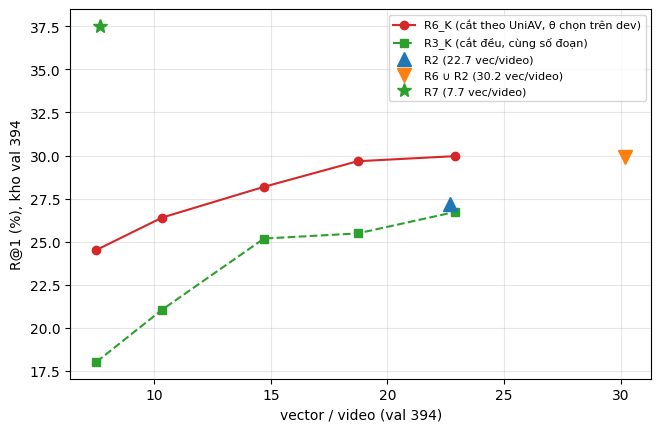

[manifest] viec4: 18.1 s


In [11]:
# ===== 11. Việc 4 =====
REFPTS = {}
def plot_budget(extra=()):
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    d = T4.sort_values('K thực tế val')
    ax.plot(d['K thực tế val'], d['R6_K R@1'], 'o-', color='C3', label='R6_K (cắt theo UniAV, θ chọn trên dev)')
    ax.plot(d['vec/video R3_K'], d['R3_K R@1'], 's--', color='C2', label='R3_K (cắt đều, cùng số đoạn)')
    for (name, (x, y)), mk in zip({**REFPTS, **dict(extra)}.items(), ('^', 'v', '*', 'D', 'P')):
        ax.plot(x, y, mk, ms=10, label=f'{name} ({x:.1f} vec/video)')
    ax.set_xlabel('vector / video (val 394)'); ax.set_ylabel('R@1 (%), kho val 394'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    fig.savefig(f'{BS}/viec4/r1_vs_vectors.png', dpi=150, bbox_inches='tight'); plt.show()

if RUN_BUDGET and PHASE == 'val':
    t0 = time.time()
    os.makedirs(f'{BS}/viec4', exist_ok=True)
    rows4 = []
    for L in [l for l in LEVELS if l['đạt']]:
        L = {**L, 'r6': f"r6_k{tag_of(L['K mục tiêu'])}", 'r3': f"r3_k{tag_of(L['K mục tiêu'])}"}
        (r6r, r6h, k6), (r3r, r3h, k3) = ranks(DBB, L['r6']), ranks(DBB, L['r3'])
        assert abs(k6 - k3) < 1e-9, 'R3_K phải có đúng số đoạn của R6_K'
        d63, d62 = pair(DBB, L['r6'], DBB, L['r3']), pair(DBB, L['r6'], DB, 'uni_chunk')
        rows4.append({'K mục tiêu': L['K mục tiêu'], 'cách': f"{L['method']} {L['param']}", 'K dev': L['K dev'], 'K thực tế val': k6,
                      'vec/video R3_K': k3, 'độ phủ R6_K val %': 100 * float(np.mean([coverage(NEW[L['r6']][v], dur[v]) for v in VAL])),
                      'chồng lấn R6_K val %': 100 * float(np.mean([overlap(NEW[L['r6']][v]) for v in VAL])),
                      'R6_K R@1': r_at(r6r), 'R3_K R@1': r_at(r3r), 'R6_K − R3_K': d63['A - B'], 'CI R6_K − R3_K': d63['CI (video)'],
                      'R6_K − R2': d62['A - B'], 'CI R6_K − R2': d62['CI (video)'], 'VCMR R@1 R6_K': 100 * float(r6h.mean()),
                      'VCMR R@1 R3_K': 100 * float(r3h.mean()), 'R6 hơn cắt đều ở K này (cận dưới CI > 0)': bool(d63['ci_low'] > 0)})
    T4 = pd.DataFrame(rows4)
    l75 = T4.set_index('K mục tiêu').loc[7.5]
    assert abs(l75['R6_K R@1'] - 24.52) <= 0.005 and abs(l75['R3_K R@1'] - 18.02) <= 0.005, 'DỪNG: mức 7.5 không tái lập 24.52 / 18.02'
    display(T4.round(2))
    print(f"chồng lấn R6_K (val): {T4['chồng lấn R6_K val %'].iloc[0]:.1f}% ở K {T4['K mục tiêu'].iloc[0]} -> "
          f"{T4['chồng lấn R6_K val %'].iloc[-1]:.1f}% ở K {T4['K mục tiêu'].iloc[-1]}; độ phủ {T4['độ phủ R6_K val %'].iloc[0]:.1f}% -> "
          f"{T4['độ phủ R6_K val %'].iloc[-1]:.1f}% (R3_K: 100%, chồng lấn 0%)")
    REFPTS = {f'{LABEL[p]}': (ranks(DB, p)[2], r_at(ranks(DB, p)[0])) for p in ('uni_chunk', 'uniav_pred+uni_chunk', 'gt')}
    plot_budget()
    T4.to_csv(f'{BS}/viec4/budget.csv', index=False)
    OUT['việc 4'] = T4
    done('viec4', t0, rows=rows4)

## Việc 5: R8 = cắt theo UniAV rồi lấp khoảng trống

**Lý do (ghi vào file kết quả):** ở bản Athena cũ, phần lớn khoảng cách R7 − R6 nằm ở các câu có bước bị UniAV bỏ sót; R6 ∪ R2 cao hơn
cả hai cho thấy hai cách cắt bổ sung cho nhau. R8 giữ ranh giới UniAV và chỉ thêm vector ở vùng UniAV không phủ.

**Lượt dev:** lưới chấm trên dev (gallery 104, caption dev), chọn bằng `pick_fill`, ghi vào khối khoá. **Lượt val:** đọc
`viec5_R8.locked`, chấm val một lần. Đổi phương pháp chính sang R8 chỉ khi cận dưới CI của R8 − R6 > 0 (val).

,dòng,R@1,R@5,R@10,VCMR R@1,vec/video,độ phủ %,bỏ sót event GT %,R@1 kho 498
0,R6,24.52,51.72,64.69,15.97,7.52,52.22,27.16,22.41
1,R8,27.39,56.86,70.86,14.32,22.15,97.44,14.19,25.05


,A - B,CI (video)
R8 − R6 (val),2.871287,"[+1.63, +4.19]"
R8 − R2 (val),0.231023,"[-1.61, +2.09]"
R8 − R6 ∪ R2 (val),-2.508251,"[-4.03, -1.05]"
R8 − R6 (all),2.640264,"[+1.52, +3.97]"
R8 − R2 (all),0.693069,"[-1.17, +2.51]"


,nhóm,câu,R6,R8,R7,R8 − R6,CI,phần đóng góp vào R8 − R6 toàn kho (điểm)
0,bước bị R6 bỏ sót,823,8.38,22.11,40.58,13.73,"[+10.97, +16.54]",3.73
1,không bỏ sót,2207,30.54,29.36,36.38,-1.18,"[-2.40, +0.13]",-0.86


{
 "locked": {
  "L_min": 5,
  "L_fill": 10
 },
 "R8 − R6 (val)": "[+1.63, +4.19]",
 "R8 − R2 (val)": "[-1.61, +2.09]",
 "phương pháp chính YC2": "R8",
 "câu R8 so với R2": "không phân biệt được R8 và R2 về R@1 (không viết 'tương đương' hay 'bằng')",
 "tăng chủ yếu ở nhóm bỏ sót": true
}
phương pháp chính YC2 = R8


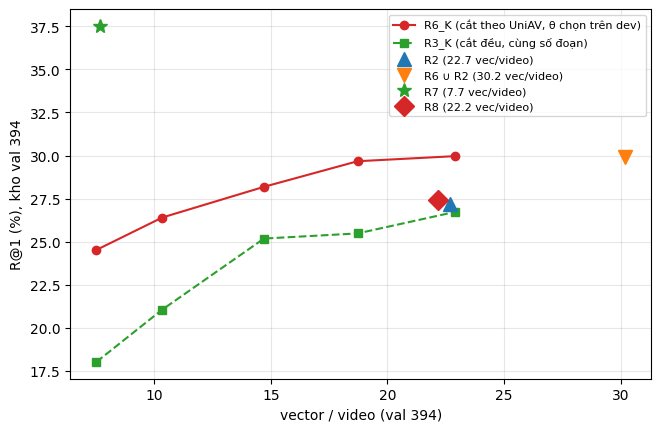

[manifest] viec5_val: 12.5 s


In [12]:
# ===== 12. Việc 5 =====
if RUN_R8 and PHASE == 'dev':
    t0 = time.time()
    os.makedirs(f'{BS}/viec5', exist_ok=True)
    k6_dev = float(np.mean([len(r6[v]) for v in DEV]))
    dev_rows = [{**g_, 'R@1 dev': r_at(ranks(DBB, g_['cấu hình'], 'dev')[0]), 'vec/video dev': ranks(DBB, g_['cấu hình'], 'dev')[2],
                 'cửa sổ lấp/video dev': ranks(DBB, g_['cấu hình'], 'dev')[2] - k6_dev} for g_ in R8_GRID]
    dev5 = pd.DataFrame(dev_rows)
    REF5 = {'R6 R@1 dev': r_at(ranks(DB, 'uniav_pred', 'dev')[0]), 'R6 vec/video dev': k6_dev,
            'R2 R@1 dev': r_at(ranks(DB, 'uni_chunk', 'dev')[0]), 'R2 vec/video dev': ranks(DB, 'uni_chunk', 'dev')[2]}
    print(json.dumps(REF5, ensure_ascii=False)); display(dev5.round(2))
    pick = pick_fill([{**r, 'R@1': r['R@1 dev'], 'vec/video': r['vec/video dev']} for r in dev_rows], tie=0.3)
    CHOICE = {'L_min': pick['L_min'], 'L_fill': pick['L_fill']}
    print('cấu hình quy tắc chọn trên dev:', CHOICE)
    LOCK_BLOCK['viec5_R8'] = {'locked': CHOICE, 'dev_grid': dev_rows, 'dev_reference': REF5}
    dev5.to_csv(f'{BS}/viec5/dev_grid.csv', index=False)
    OUT['việc 5 dev'] = dev5
    done('viec5_dev', t0, choice=CHOICE)
if RUN_R8 and PHASE == 'val':
    t0 = time.time()
    os.makedirs(f'{BS}/viec5', exist_ok=True)
    r8r, r8h, k8 = ranks(DBB, 'r8')
    r6r, r6h, k6 = ranks(DB, 'uniav_pred')
    def desc(name, db, p, part):
        rk, hit, k = ranks(db, p)
        return {'dòng': name, 'R@1': r_at(rk), 'R@5': r_at(rk, 5), 'R@10': r_at(rk, 10), 'VCMR R@1': 100 * float(hit.mean()),
                'vec/video': k, 'độ phủ %': 100 * float(np.mean([coverage(part[v], dur[v]) for v in VAL])),
                'bỏ sót event GT %': miss_rate({v: part[v] for v in VAL}, gt_val, MISS_T), 'R@1 kho 498': r_at(ranks(db, p, 'all')[0])}
    t5 = pd.DataFrame([desc('R6', DB, 'uniav_pred', r6), desc('R8', DBB, 'r8', NEW['r8'])])
    display(t5.round(2))
    P5 = {f'R8 − {LABEL[b]} ({g_})': pair(DBB, 'r8', DB, b, g_) for b, g_ in
          (('uniav_pred', 'val'), ('uni_chunk', 'val'), ('uniav_pred+uni_chunk', 'val'), ('uniav_pred', 'all'), ('uni_chunk', 'all'))}
    p5 = pd.DataFrame(P5).T
    display(p5[['A - B', 'CI (video)']].round(2))
    r7r = ranks(DB, 'gt')[0]
    grp = []
    for gname, m in (('bước bị R6 bỏ sót', MISSED_Q), ('không bỏ sót', ~MISSED_Q)):
        bs = boot(r8r[m], r6r[m], text['video_id'][m])
        grp.append({'nhóm': gname, 'câu': int(m.sum()), 'R6': r_at(r6r[m]), 'R8': r_at(r8r[m]), 'R7': r_at(r7r[m]),
                    'R8 − R6': bs['A - B'], 'CI': bs['CI (video)'],
                    'phần đóng góp vào R8 − R6 toàn kho (điểm)': 100 * float(((r8r[m] <= 1).sum() - (r6r[m] <= 1).sum()) / len(r8r))})
    grp = pd.DataFrame(grp)
    display(grp.round(2))
    d86, d82 = P5['R8 − R6 (val)'], P5['R8 − R2 (val)']
    MAIN = 'R8' if d86['ci_low'] > 0 else 'R6 MaxSim'
    S = PB['viec5_R8']['sentences_R8_vs_R2']
    sent = (S['ci_low > 0'].replace('X', f'{k8:.2f}') if d82['ci_low'] > 0 else S['ci_high < 0'] if d82['ci_high'] < 0
            else S['ci contains 0'])
    VERDICT = {'locked': LOCKED, 'R8 − R6 (val)': d86['CI (video)'], 'R8 − R2 (val)': d82['CI (video)'],
               'phương pháp chính YC2': MAIN, 'câu R8 so với R2': sent,
               'tăng chủ yếu ở nhóm bỏ sót': bool(grp.iloc[0]['phần đóng góp vào R8 − R6 toàn kho (điểm)'] >
                                                  grp.iloc[1]['phần đóng góp vào R8 − R6 toàn kho (điểm)'])}
    print(json.dumps(VERDICT, indent=1, ensure_ascii=False))
    print(f'phương pháp chính YC2 = {MAIN}')
    t5.to_csv(f'{BS}/viec5/val.csv', index=False); p5.to_csv(f'{BS}/viec5/val_pairs.csv')
    grp.to_csv(f'{BS}/viec5/val_by_miss_group.csv', index=False)
    json.dump(VERDICT, open(f'{BS}/viec5/verdict.json', 'w'), indent=1, ensure_ascii=False)
    OUT['việc 5 val'], OUT['việc 5 cặp'], OUT['việc 5 nhóm'] = t5, p5[['A - B', 'CI (video)']].reset_index(), grp
    if RUN_BUDGET:
        plot_budget([('R8', (k8, r_at(r8r)))])
    done('viec5_val', t0, locked=LOCKED, main=MAIN)

## (lượt val) Việc 6: R5b, biến thể kiểu đa dạng nội dung

Cùng medoid với R5 (K = số đoạn R6), mỗi medoid một cửa sổ dài thời lượng / K, cắt gọn trong video. Chỉ mô tả.

In [13]:
# ===== 13. Việc 6 =====
if RUN_R5B and PHASE == 'val':
    t0 = time.time()
    os.makedirs(f'{BS}/viec6', exist_ok=True)
    rows6 = []
    for name, db, p, part in (('R5b', DBB, 'r5b', NEW['r5b']), ('R5 kmedoids_M', DB, 'kmedoids_M', km), ('R3 uni_M', DB, 'uni_M', uni_M),
                              ('R6 uniav_pred', DB, 'uniav_pred', r6)):
        rk, hit, k = ranks(db, p)
        rows6.append({'dòng': name, 'R@1': r_at(rk), 'R@5': r_at(rk, 5), 'VCMR R@1': 100 * float(hit.mean()), 'vec/video': k,
                      'độ phủ %': 100 * float(np.mean([coverage(part[v], dur[v]) for v in VAL]))})
    t6 = pd.DataFrame(rows6)
    p6 = pd.DataFrame({'R6 − R5b': pair(DB, 'uniav_pred', DBB, 'r5b'), 'R5b − R5': pair(DBB, 'r5b', DB, 'kmedoids_M'),
                       'R5b − R3': pair(DBB, 'r5b', DB, 'uni_M')}).T[['A - B', 'CI (video)']]
    display(t6.round(2)); display(p6.round(2))
    t6.to_csv(f'{BS}/viec6/r5b.csv', index=False); p6.to_csv(f'{BS}/viec6/r5b_pairs.csv')
    OUT['việc 6'], OUT['việc 6 cặp'] = t6, p6.reset_index()
    done('viec6', t0)

,dòng,R@1,R@5,VCMR R@1,vec/video,độ phủ %
0,R5b,18.22,43.73,6.47,7.52,75.55
1,R5 kmedoids_M,12.94,32.64,0.20,7.52,5.73
2,R3 uni_M,18.02,44.42,6.07,7.52,100.00
3,R6 uniav_pred,24.52,51.72,15.97,7.52,52.22


,A - B,CI (video)
R6 − R5b,6.30363,"[+4.36, +8.17]"
R5b − R5,5.280528,"[+3.61, +7.10]"
R5b − R3,0.19802,"[-1.40, +1.92]"


[manifest] viec6: 3.0 s


## (lượt val) Việc 7: Omni `pt` với Athena sạch

`pt` của AZ ô 16 đã có R0, R3, R6, R7; ở đây thêm R2 (và R8 nếu đã khoá) vào cùng store `pt/raw`, gom `segments.npz` riêng. `assert` R0,
R3, R6, R7 trùng `exp1_a_pt.csv` của AZ.

In [14]:
# ===== 14. Việc 7 =====
if RUN_PT and PHASE == 'val':
    t0 = time.time()
    os.makedirs(f'{BS}/viec7', exist_ok=True)
    if prep_pt['segs_todo']:
        enc = omni_env('pt')
        write_jsonl(cfg_bs_pt.segs_todo, prep_pt['segs_todo'])
        copy_videos(sorted({q['video'].removesuffix('.mp4') for q in prep_pt['segs_todo']}))
        encode('av', cfg_bs_pt.segs_todo, cfg_bs_pt.av_store, f'{BS}/encode_pt.log', enc, '--num-workers 4')
        RUN['encoded']['pt (việc 7)'] = len(prep_pt['segs_todo'])
        prep_pt = prepare(cfg_bs_pt, write=False, verbose=False)
    assert not prep_pt['segs_todo']
    DBP_AZ = str(local_npz(DBH_PT, f'/content/db_pt_{H8}', ('text.npz',)))
    DBPB = fresh_db(prep_pt['rows'], cfg_bs_pt.av_store, '/content/db_bs_pt_val', str(cfg_bs_pt.out_dir), [(f'{DBP_AZ}/text.npz', 'text.npz')])
    PT_ROWS = ['global', 'uni_M', 'uniav_pred', 'gt', 'uni_chunk'] + (['r8'] if R8_NAME else [])
    t7 = pd.DataFrame([{'dòng': LABEL[p], 'R@1': r_at(ranks(DBPB, p)[0]), 'R@5': r_at(ranks(DBPB, p)[0], 5),
                        'R@10': r_at(ranks(DBPB, p)[0], 10), 'vec/video': ranks(DBPB, p)[2]} for p in PT_ROWS])
    az_pt = pd.read_csv(f'{RES_NEW}/exp1_a_pt.csv').set_index('partition')['R@1']
    bad = {p: (r_at(ranks(DBPB, p)[0]), az_pt[p]) for p in ('global', 'uni_M', 'uniav_pred', 'gt') if abs(r_at(ranks(DBPB, p)[0]) - az_pt[p]) > 0.005}
    assert not bad, f'pt khác exp1_a_pt.csv của AZ: {bad}'
    p7 = pd.DataFrame({'R6 − R0': pair(DBPB, 'uniav_pred', DBPB, 'global'), 'R6 − R3': pair(DBPB, 'uniav_pred', DBPB, 'uni_M'),
                       'R7 − R6': pair(DBPB, 'gt', DBPB, 'uniav_pred')}).T[['A - B', 'CI (video)']]
    print('=== Omni pt, kho val 394 ==='); display(t7.round(2)); display(p7.round(2))
    t7.to_csv(f'{BS}/viec7/pt.csv', index=False); p7.to_csv(f'{BS}/viec7/pt_pairs.csv')
    OUT['việc 7'], OUT['việc 7 cặp'] = t7, p7.reset_index()
    done('viec7', t0, encoded=RUN['encoded'].get('pt (việc 7)', 0))

=== Omni pt, kho val 394 ===


,dòng,R@1,R@5,R@10,vec/video
0,R0,7.89,24.03,35.78,1.00
1,R3,16.44,40.76,55.28,7.52
2,R6,19.21,44.62,58.61,7.52
3,R7,25.31,54.52,68.12,7.69
4,R2,20.92,50.83,65.31,22.66
5,R8,20.59,47.99,62.18,22.15


,A - B,CI (video)
R6 − R0,11.320132,"[+9.52, +13.09]"
R6 − R3,2.772277,"[+0.97, +4.49]"
R7 − R6,6.105611,"[+4.32, +7.81]"


[manifest] viec7: 23.6 s


## (lượt val) Việc 8: Exp 4, bỏ âm thanh lúc suy luận (phía Omni)

**Cách bỏ âm thanh** (`encode.py --no-audio`): đầu vào chỉ-hình của chính Omni-fix, `_prepare_submodal_input({'video'})` (nhánh
Tuple-InfoNCE): prompt không có token `<|AUDIO|>`, không tensor âm thanh, `use_audio_in_video = False`; forward của Qwen2.5-Omni nhận
được đầu vào này. Mỗi clip `assert` prompt chỉ-hình = prompt AV bỏ token âm thanh (cùng template). Không phải âm thanh im lặng (bản cũ
`--silence`). Δ được gọi là **"bỏ âm thanh lúc suy luận"**, không phải "mô hình không dùng âm thanh": cả `ft` (fine-tune trên cặp video + âm
thanh, tuple loss tắt) và `pt` đều chưa từng thấy đầu vào chỉ hình. UniAV giữ nguyên (Athena dùng âm thanh). Thử 5 clip trước; lỗi ở bước này là **điều kiện dừng**.

In [15]:
# ===== 15. Việc 8 =====
if RUN_AUDIO and PHASE == 'val':
    t0 = time.time()
    os.makedirs(f'{BS}/viec8', exist_ok=True)
    enc = omni_env('ft')
    probe = [q for q in db_rows(DB, ['uniav_pred'], VAL)][:5]
    PROBE = '/content/probe_noaudio'
    shutil.rmtree(PROBE, ignore_errors=True); os.makedirs(PROBE)
    write_jsonl(f'{PROBE}/segs.jsonl', segment_records(unique_segments(probe), set()))
    copy_videos(sorted({q['video_id'] for q in probe}))
    try:
        encode('av', f'{PROBE}/segs.jsonl', f'{PROBE}/av', f'{PROBE}/encode.log', enc, '--num-workers 0 --no-audio')
    except RuntimeError as e:
        raise RuntimeError(f'DỪNG (việc 8): không encode được chỉ hình theo nhánh của mô hình: {e}. Báo người dùng, '
                           'không tự chuyển sang cách xấp xỉ.')
    fresh = read_store(f'{PROBE}/av', 'av')
    with np.load(f'{DB}/segments.npz') as b:
        row, E = {k: i for i, k in enumerate(b['seg_key'].tolist())}, b['emb']      # emb đọc một lần
    av = {k: E[row[k]].astype(np.float32) for k in fresh}
    cos = {k: float(fresh[k] @ av[k] / np.linalg.norm(fresh[k]) / np.linalg.norm(av[k])) for k in fresh}
    print('thử 5 clip: cos(bỏ âm thanh lúc suy luận, có âm thanh) =', {k.split('__')[1]: round(c, 4) for k, c in cos.items()})
    assert all(np.isfinite(v).all() for v in fresh.values()) and max(cos.values()) < 0.9999, 'vector bỏ âm thanh phải hữu hạn và khác bản có âm thanh'
    parts8 = AUDIO_PARTS + (['r8'] if MAIN == 'R8' else [])
    rows8 = db_rows(DB, AUDIO_PARTS, VAL) + (db_rows(DBB, ['r8'], VAL) if MAIN == 'R8' else [])
    todo8 = segment_records(unique_segments(rows8), store_keys(STORE_NA, 'av'))
    print('clip bỏ âm thanh cần encode:', len(todo8))
    if todo8:
        write_jsonl('/content/noaudio_todo.jsonl', todo8)
        copy_videos(sorted(VAL))
        encode('av', '/content/noaudio_todo.jsonl', STORE_NA, f'{BS}/encode_noaudio.log', enc, '--num-workers 4 --no-audio')
        RUN['encoded']['ft bỏ âm thanh (việc 8)'] = len(todo8)
    DBN = fresh_db(rows8, STORE_NA, '/content/db_noaudio', f'{BS}/viec8/db', [(f'{DB}/text.npz', 'text.npz')])
    rows8t = []
    for p in parts8:
        a, n_ = ranks(DBB if p == 'r8' else DB, p)[0], ranks(DBN, p)[0]
        bs = boot(a, n_, text['video_id'])
        rows8t.append({'dòng': LABEL[p], 'R@1 có âm thanh': r_at(a), 'R@1 bỏ âm thanh lúc suy luận': r_at(n_),
                       'Δ có − bỏ âm thanh lúc suy luận': bs['A - B'], 'CI': bs['CI (video)']})
    t8 = pd.DataFrame(rows8t)
    p8 = pd.DataFrame({'R6 − R3 có âm thanh': pair(DB, 'uniav_pred', DB, 'uni_M'),
                       'R6 − R3 bỏ âm thanh lúc suy luận': pair(DBN, 'uniav_pred', DBN, 'uni_M')}).T[['A - B', 'CI (video)']]
    display(t8.round(2)); display(p8.round(2))
    t8.to_csv(f'{BS}/viec8/audio.csv', index=False); p8.to_csv(f'{BS}/viec8/audio_pairs.csv')
    json.dump({'probe_cos': cos, 'method': PB['viec8_audio']['method'], 'wording': PB['viec8_audio']['wording']}, open(f'{BS}/viec8/probe.json', 'w'), indent=1, ensure_ascii=False)
    OUT['việc 8'], OUT['việc 8 cặp'] = t8, p8.reset_index()
    done('viec8', t0, probe_cos=cos, encoded=RUN['encoded'].get('ft bỏ âm thanh (việc 8)', 0))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 88.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 108.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 45.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 144.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 69.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.

af0842845b3554cc.incomplete'

Fetching 26 files:  58%|█████▊    | 15/26 [00:30<00:

,dòng,R@1 có âm thanh,R@1 bỏ âm thanh lúc suy luận,Δ có − bỏ âm thanh lúc suy luận,CI
0,R0,8.32,7.03,1.29,"[+0.16, +2.44]"
1,R3,18.02,12.54,5.48,"[+3.86, +6.94]"
2,R6,24.52,16.20,8.32,"[+6.62, +9.95]"
3,R7,37.52,21.95,15.58,"[+13.63, +17.42]"
4,R8,27.39,16.73,10.66,"[+8.87, +12.46]"


,A - B,CI (video)
R6 − R3 có âm thanh,6.50165,"[+4.51, +8.47]"
R6 − R3 bỏ âm thanh lúc suy luận,3.663366,"[+2.09, +5.07]"


[manifest] viec8: 4800.9 s


## (lượt val) Việc 9: backbone ngoài, CLIP ViT-L/14 zero-shot

`open_clip` ViT-L-14, trọng số `openai`, không tinh chỉnh. Vector đoạn = trung bình 8 khung lấy **đúng cách Omni lấy khung**
(`frame_index` = `video_decord`), mỗi khung L2-normalise; câu hỏi qua text encoder của CLIP; cosine, MaxSim. Kho val 394. Vector ghi
lên Drive theo lô 25 video (`bo_sung/clip/seg_*.npz`), chạy lại thì bỏ qua clip đã có.

**Cài đặt không đụng môi trường Omni:** `pip install --no-deps open_clip_torch==2.24.0 ftfy==6.2.0`; in phiên bản torch,
torchvision, transformers và các thư viện Omni trước / sau. Bản nào đổi, hoặc `import open_clip` lỗi: **bỏ qua việc 9** (ghi trong
log), các ô khác chạy tiếp (việc 10 bỏ cột CLIP).

In [16]:
# ===== 16. Việc 9 =====
if RUN_CLIP and PHASE == 'val':
    t0 = time.time()
    os.makedirs(f'{BS}/viec9', exist_ok=True)
    if not os.path.exists('/content/.fushion_deps_ok'):           # decord (lấy khung như Omni) nằm trong requirements.txt
        sh(f'pip install -q -r {FUSHION}/requirements.txt')
        open('/content/.fushion_deps_ok', 'w').close()
    PKGS = ('torch', 'torchvision', 'transformers', 'tokenizers', 'accelerate', 'peft', 'safetensors', 'huggingface_hub', 'numpy',
            'decord', 'av', 'librosa', 'timm', 'regex', 'protobuf', 'sentencepiece')
    def versions():
        prog = ('import json, importlib.metadata as m\nout = {}\nfor p in %r:\n    try: out[p] = m.version(p)\n'
                '    except Exception: out[p] = None\nprint(json.dumps(out))' % (PKGS,))
        return json.loads(subprocess.run([sys.executable, '-c', prog], capture_output=True, text=True).stdout.strip().splitlines()[-1])
    V_BEFORE = versions()
    sh('pip install -q --no-deps open_clip_torch==2.24.0 ftfy==6.2.0', check=False)
    V_AFTER = versions()
    chk = subprocess.run([sys.executable, '-c', 'import open_clip, ftfy, torch, torchvision; print(open_clip.__version__)'],
                         capture_output=True, text=True)
    CHANGED = {p: (V_BEFORE[p], V_AFTER[p]) for p in PKGS if V_BEFORE[p] != V_AFTER[p]}
    print('phiên bản trước:', V_BEFORE); print('phiên bản sau :', V_AFTER)
    CLIP_OK = not CHANGED and chk.returncode == 0
    json.dump({'before': V_BEFORE, 'after': V_AFTER, 'changed': CHANGED, 'import': chk.stdout.strip() or chk.stderr[-1500:]},
              open(f'{BS}/viec9/env_check.json', 'w'), indent=1)
    if not CLIP_OK:
        print('BỎ QUA việc 9: cài open_clip làm đổi', CHANGED or '(không đổi bản nào)', '| import:', chk.stderr[-800:] or 'OK')
        done('viec9', t0, skipped=True, changed=CHANGED)
if RUN_CLIP and PHASE == 'val' and CLIP_OK:
    t0 = time.time()
    import open_clip, decord
    from PIL import Image as PILImage
    model_c, _, preprocess = open_clip.create_model_and_transforms('ViT-L-14', pretrained='openai', device='cuda')
    model_c = model_c.eval().half()
    tok = open_clip.get_tokenizer('ViT-L-14')
    CLIP_INFO = {'open_clip': open_clip.__version__, 'model': 'ViT-L-14', 'pretrained': 'openai', 'frames': 8, 'dtype': 'fp16'}
    print(CLIP_INFO)
    os.makedirs(CLIP_DIR, exist_ok=True)
    parts9 = CLIP_PARTS + (['r8'] if R8_NAME else [])
    rows9 = db_rows(DB, CLIP_PARTS, VAL) + (db_rows(DBB, ['r8'], VAL) if R8_NAME else [])
    have = clip_store()
    todo_v = defaultdict(list)
    for k, s in unique_segments(rows9).items():
        if k not in have:
            todo_v[s['video_id']].append((k, s['ts'], s['te']))
    print('CLIP: clip cần encode', sum(map(len, todo_v.values())), 'trong', len(todo_v), 'video')
    copy_videos(sorted(todo_v))

    @torch.no_grad()
    def embed_frames(frames):
        x = torch.stack([preprocess(PILImage.fromarray(f)) for f in frames]).cuda().half()
        e = model_c.encode_image(x).float()
        return (e / e.norm(dim=-1, keepdim=True)).cpu().numpy()

    buf_k, buf_e, fails, n_frames, n_done, t_enc = [], [], [], 0, 0, time.time()
    for i, v in enumerate(sorted(todo_v), 1):
        vr = decord.VideoReader(f'/content/videos/{v}.mp4', num_threads=4)
        fps, n = vr.get_avg_fps(), len(vr)
        idx_of = {}
        for k, ts, te in todo_v[v]:
            try:
                idx_of[k] = frame_index(ts, te, fps, n)
            except ValueError as e:
                fails.append({'id': k, 'error': str(e)})
        uniq = np.unique(np.concatenate(list(idx_of.values()))) if idx_of else np.array([], int)
        emb = {}
        for s in range(0, len(uniq), 64):
            part = uniq[s:s + 64]
            emb.update(zip(part.tolist(), embed_frames(vr.get_batch(part.tolist()).asnumpy())))
        n_frames += len(uniq)
        for k, ix in idx_of.items():
            m_ = np.mean([emb[j] for j in ix.tolist()], axis=0)
            buf_k.append(k); buf_e.append((m_ / np.linalg.norm(m_)).astype(np.float16))
        if buf_k and (i % 25 == 0 or i == len(todo_v)):
            np.savez(f'{CLIP_DIR}/seg_{time.strftime("%Y%m%d-%H%M%S")}_{i:04d}.npz', seg_key=np.array(buf_k), emb=np.stack(buf_e))
            n_done += len(buf_k); buf_k, buf_e = [], []
            print(f'[clip] {i}/{len(todo_v)} video | {n_done} clip | {n_frames} khung | {(time.time() - t_enc) / max(n_done, 1):.3f} s/clip', flush=True)
    if fails:
        write_jsonl(f'{CLIP_DIR}/failed.jsonl', fails)
    assert not fails, f'{len(fails)} clip CLIP lỗi (xem {CLIP_DIR}/failed.jsonl)'
    if n_done:
        RUN['encoded']['CLIP (việc 9)'] = n_done
        CLIP_INFO['s/clip'] = (time.time() - t_enc) / n_done
    tpath = f'{CLIP_DIR}/text.npz'
    if not os.path.exists(tpath):
        with torch.no_grad():
            te_ = np.concatenate([model_c.encode_text(tok(text['sentence'][s:s + 256].tolist()).cuda()).float().cpu().numpy()
                                  for s in range(0, len(text['sentence']), 256)])
        te_ /= np.linalg.norm(te_, axis=1, keepdims=True)
        np.savez(tpath, **{k: text[k] for k in ('caption_id', 'video_id', 'sentence', 'gt_ts', 'gt_te', 'gt_seg_key')}, emb=te_.astype(np.float16))
    have = clip_store()
    assert all(q['seg_key'] in have for q in rows9), 'thiếu vector CLIP'
    DBC = '/content/db_clip'
    os.makedirs(DBC, exist_ok=True)
    np.savez(f'{DBC}/segments.npz', keys=np.array([q['key'] for q in rows9]), seg_key=np.array([q['seg_key'] for q in rows9]),
             video_id=np.array([q['video_id'] for q in rows9]), partition=np.array([q['partition'] for q in rows9]),
             ts=np.array([q['ts'] for q in rows9], np.float32), te=np.array([q['te'] for q in rows9], np.float32),
             emb=np.stack([have[q['seg_key']] for q in rows9]))
    shutil.copy2(tpath, f'{DBC}/text.npz')
    t9 = pd.DataFrame([{'dòng': LABEL[p], 'R@1': r_at(ranks(DBC, p)[0]), 'R@5': r_at(ranks(DBC, p)[0], 5),
                        'R@10': r_at(ranks(DBC, p)[0], 10), 'vec/video': ranks(DBC, p)[2]} for p in parts9])
    p9 = pd.DataFrame({'R6 − R3': pair(DBC, 'uniav_pred', DBC, 'uni_M'), 'R6 − R0': pair(DBC, 'uniav_pred', DBC, 'global'),
                       'R7 − R6': pair(DBC, 'gt', DBC, 'uniav_pred')}).T[['A - B', 'CI (video)']]
    print('=== CLIP ViT-L/14 zero-shot, kho val 394 ==='); display(t9.round(2)); display(p9.round(2))
    t9.to_csv(f'{BS}/viec9/clip.csv', index=False)
    p9.to_csv(f'{BS}/viec9/clip_pairs.csv')
    json.dump(CLIP_INFO, open(f'{BS}/viec9/clip_info.json', 'w'), indent=1)
    OUT['việc 9'], OUT['việc 9 cặp'] = t9, p9.reset_index()
    done('viec9', t0, **CLIP_INFO)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 24.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.4/54.4 kB 5.9 MB/s eta 0:00:00

phiên bản trước: {'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'transformers': '4.51.3', 'tokenizers': '0.21.4', 'accelerate': '1.15.0', 'peft': '0.21.2', 'safetensors': '0.8.0', 'huggingface_hub': '0.36.2', 'numpy': '2.1.3', 'decord': '0.6.0', 'av': '19.0.2', 'librosa': '0.11.0', 'timm': '1.0.30', 'regex': '2025.11.3', 'protobuf': '6.33.6', 'sentencepiece': '0.2.2'}
phiên bản sau : {'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'transformers': '4.51.3', 'tokenizers': '0.21.4', 'accelerate': '1.15.0', 'peft': '0.21.2', 'safetensors': '0.8.0', 'huggingface_hub': '0.36.2', 'numpy': '2.1.3', 'decord': '0.6.0', 'av': '19.0.2', 'librosa': '0.11.0', 'timm': '1.0.30', 'regex': '2025.11.3', 'protobuf': '6.33.6', 'sentencepiece': '0.2.2'}
BỎ QUA việc 9: cài open_clip làm đổi (không đổi bản nào) | import: /usr/local/lib/p

## (lượt val) Việc 10: text → clip GT (số để định vị)

Mỗi caption val tìm đúng clip GT của nó trong 3.030 clip GT của val (`text_to_clip`, gallery `eval`, như `eval_youcookii.py`).

**Khác protocol thường dùng trong bài báo:** chỉ 394 video val có trong dữ liệu (không phải đủ bộ val gốc); clip cắt theo GT đã kẹp
vào thời lượng mp4, 8 khung + 8 s âm thanh; Omni `ft` đã học clip GT của trainsplit (cùng phân phối với clip GT val); bảng chính của
UEMR là câu → video trong kho 394, không phải bài này.

**Số đã công bố:** không điền từ trí nhớ.

| Công trình | Protocol | R@1 | R@5 | R@10 | MdR | Nguồn |
|---|---|---|---|---|---|---|
| (người dùng bổ sung) | | | | | | |

In [17]:
# ===== 17. Việc 10 =====
if RUN_CLIPRET and PHASE == 'val':
    t0 = time.time()
    os.makedirs(f'{BS}/viec10', exist_ok=True)
    rows10 = []
    for name, db in (('Omni ft (checkpoint-1948)', DB), ('Omni pt (OmniRetriever-7B)', DBPB if RUN_PT else None),
                     ('CLIP ViT-L/14 (openai), 8 khung', DBC if RUN_CLIP and CLIP_OK else None)):
        if db is None:
            rows10.append({'mô hình': name, 'ghi chú': 'không chạy (cờ tắt hoặc việc 9 bị bỏ qua)'})
            continue
        r = text_to_clip(db)['eval']
        assert r['gallery'] == 3030
        rows10.append({'mô hình': name, 'clip': r['gallery'], 'R@1': r['R@1'], 'R@5': r['R@5'], 'R@10': r['R@10'], 'MdR': r['MedR']})
    t10 = pd.DataFrame(rows10)
    display(t10.round(2))
    t10.to_csv(f'{BS}/viec10/text_to_clip.csv', index=False)
    OUT['việc 10'] = t10
    done('viec10', t0)

,mô hình,clip,R@1,R@5,R@10,MdR,ghi chú
0,Omni ft (checkpoint-1948),3030.0,35.64,65.68,75.91,3.0,NaN
1,Omni pt (OmniRetriever-7B),3030.0,22.41,49.21,61.02,6.0,NaN
2,"CLIP ViT-L/14 (openai), 8 khung",NaN,NaN,NaN,NaN,NaN,không chạy (cờ tắt hoặc việc 9 bị bỏ qua)


[manifest] viec10: 2.0 s


In [18]:
# ===== 18. run_manifest.json, bảng tổng hợp =====
def md_table(df, nd=2):
    d = df.copy()
    fmt = lambda x: f'{x:.{nd}f}' if isinstance(x, (float, np.floating)) and x == x else ('' if x is None or (isinstance(x, float) and x != x) else str(x))
    return ('| ' + ' | '.join(map(str, d.columns)) + ' |\n|' + '---|' * len(d.columns) + '\n'
            + '\n'.join('| ' + ' | '.join(fmt(x) for x in r) + ' |' for r in d.itertuples(index=False)))
RUN['finished'], RUN['total_sec'] = time.strftime('%Y-%m-%d %H:%M:%S'), round(time.time() - T_START, 1)
RUN['main_method'] = MAIN
json.dump({**MAN, 'runs': MAN['runs'] + [RUN]}, open(MAN_PATH, 'w'), indent=1, default=str, ensure_ascii=False)
lines = [f'# Số liệu bổ sung UEMR YC2 (Athena {ATHENA_H8}, UniAV {H8})\n',
         f'Code {COMMIT}; bo_sung_protocol {PB_SHA} (commit {PB_COMMIT}); final_protocol {PROTO_SHA}; R8 khoá: {LOCKED}.\n']
for k, df in OUT.items():
    lines += [f'\n## {k}\n', md_table(df)]
lines.append(f'\nphương pháp chính YC2 = {MAIN or "(lượt dev: chưa chấm val)"}\n')
open(f'{BS}/so_lieu_bo_sung_{PHASE}.md', 'w').write('\n'.join(lines))
print('\n'.join(lines))
print(json.dumps({k: RUN[k] for k in ('encoded', 'sec', 'flags')}, indent=1, ensure_ascii=False))
if PHASE == 'dev':
    json.dump(LOCK_BLOCK, open(f'{BS}/lock_block_dev.json', 'w'), indent=1, ensure_ascii=False)
    print('\n===== KHỐI KHOÁ (lượt dev): chép vào configs/bo_sung_protocol.json, commit, rồi chạy PHASE = "val" =====')
    print(json.dumps(LOCK_BLOCK, indent=1, ensure_ascii=False, default=float))
    print('===== HẾT KHỐI KHOÁ =====')

# Số liệu bổ sung UEMR YC2 (Athena 961f1a89, UniAV a793d2c4)

Code 337eb81 bo_sung_protocol: khoá θ việc 4 (5 mức) và R8 (L_min 5, L_fill 10) từ lượt dev; notebook kèm output lượt dev; bo_sung_protocol 12daed1203e55fea (commit 337eb81 2026-10-22); final_protocol 133125b9549bc74a; R8 khoá: {'L_min': 5, 'L_fill': 10}.


## tái lập

| dòng | R@1 | tham chiếu |
|---|---|---|
| R0 | 8.32 | 8.32 |
| R3 | 18.02 | 18.02 |
| R2 | 27.16 | 27.16 |
| R6 | 24.52 | 24.52 |
| R7 | 37.52 | 37.52 |

## việc 4

| K mục tiêu | cách | K dev | K thực tế val | vec/video R3_K | độ phủ R6_K val % | chồng lấn R6_K val % | R6_K R@1 | R3_K R@1 | R6_K − R3_K | CI R6_K − R3_K | R6_K − R2 | CI R6_K − R2 | VCMR R@1 R6_K | VCMR R@1 R3_K | R6 hơn cắt đều ở K này (cận dưới CI > 0) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 7.50 | theta 0.4 | 6.99 | 7.52 | 7.52 | 52.22 | 3.03 | 24.52 | 18.02 | 6.50 | [+4.51, +8.47] | -2.64 | [-4.70, -0.57] | 15.97 | 6.07 | True |
| 10.00 | theta 0.34 | 9.88 | 